### setup project, show some of data

In [2]:
import pandas as pd
url = "https://raw.githubusercontent.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection/master/re_dataset.csv"
df = pd.read_csv(url, encoding="latin-1")

# df.head()
sub_cols = df.columns[3:]
def summarize_sublabels(row):
    active = [c.replace("HS_", "") for c in sub_cols if row[c] == 1]
    return ", ".join(active) if active else "-"

samples = df.groupby(["HS", "Abusive"], group_keys=False).sample(n=2, random_state=42)
samples["Sub-labels"] = samples.apply(summarize_sublabels, axis=1)

samples[["Tweet", "HS", "Abusive", "Sub-labels"]]

,Tweet,HS,Abusive,Sub-labels
462,USER Pernah ngelakuin dosa apa ya anis dan san...,0,0,-
1752,Sebelumnya 3 bank BUMN tersebut meminjam uang ...,0,0,-
5084,USER heleh \n\nmodar sana hush',0,1,-
10931,RT USER: https:// #ngentot 1 ronde setelah sub...,0,1,-
10544,Pengusaha china ;: jk reklamasi pulau G Dibata...,1,0,"Individual, Other, Strong"
662,USER USER USER USER Pencipta hoaxs ya presiden...,1,0,"Individual, Other, Weak"
6132,USER sumpah weh pastu yang bertenggek kat coun...,1,1,"Individual, Other, Weak"
4517,"Tyas Mirasih ? Pecun gitu, dulu bareng sama ak...",1,1,"Individual, Gender, Weak"


### check duplicate kata

In [3]:
label_cols = list(df.columns[1:])
dup_mask = df["Tweet"].duplicated(keep=False)

print("Fully identical rows (text + labels):", df.duplicated().sum())

Fully identical rows (text + labels): 125


In [4]:
dup_rows = df[dup_mask].copy()
dup_rows["n_copies"] = dup_rows.groupby("Tweet")["Tweet"].transform("size")

dup_rows.sort_values(["n_copies", "Tweet"], ascending=[False, True])[["Tweet", "n_copies", "HS", "Abusive"]]

,Tweet,n_copies,HS,Abusive
377,USER USER USER USER USER USER USER USER USER U...,9,0,0
1840,USER USER USER USER USER USER USER USER USER U...,9,0,0
2514,USER USER USER USER USER USER USER USER USER U...,9,0,0
4830,USER USER USER USER USER USER USER USER USER U...,9,0,0
5388,USER USER USER USER USER USER USER USER USER U...,9,0,0
...,...,...,...,...
1433,"perempuan kaya lo mending mati aja deh, jelek ...",2,1,1
5182,tangkap ahok dan klompok nya yg melakukan pema...,2,1,0
8544,tangkap ahok dan klompok nya yg melakukan pema...,2,1,0
9065,"~; Yg jelas, klw ada foto2 yg begitu:; #lombaT...",2,0,0


In [5]:
conflicts = dup_rows.groupby("Tweet").filter(
    lambda g: len(g[label_cols].drop_duplicates()) > 1
)

print("Conflicting texts:", conflicts["Tweet"].nunique(), "| rows:", len(conflicts))

conflicts.sort_values("Tweet")[["Tweet"] + label_cols]

Conflicting texts: 21 | rows: 57


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
3197,"Bro USER, ente sebut 'Kitab Suci' fiksi berart...",1,0,1,0,1,0,0,0,0,1,0,0
3363,"Bro USER, ente sebut 'Kitab Suci' fiksi berart...",1,1,1,0,1,0,0,0,0,1,0,0
863,Ekonomi dipegang Gerindra? Bisa hancur negara ...,1,1,0,1,0,0,0,0,1,0,1,0
2911,Ekonomi dipegang Gerindra? Bisa hancur negara ...,0,0,0,0,0,0,0,0,0,0,0,0
3680,GAPERNAH MENDALAMI AL-QURAN YA BANG??? PANTESA...,1,1,1,0,1,0,1,0,0,1,0,0
2078,GAPERNAH MENDALAMI AL-QURAN YA BANG??? PANTESA...,1,1,1,0,1,0,0,0,0,1,0,0
40,GAPERNAH MENDALAMI AL-QURAN YA BANG??? PANTESA...,1,1,1,0,1,0,1,0,0,1,0,0
4938,GAPERNAH MENDALAMI AL-QURAN YA BANG??? PANTESA...,1,1,1,0,1,0,0,0,0,1,0,0
2819,"Kang USER ,fakta hari ini,partai pendukung si ...",1,0,0,1,1,0,0,0,0,0,1,0
10037,"Kang USER ,fakta hari ini,partai pendukung si ...",1,0,0,1,0,0,0,0,1,0,1,0


In [6]:
dup_mask = df["Tweet"].duplicated(keep=False)
label_variants = (
    df[dup_mask]
    .groupby("Tweet")[["HS", "Abusive"]]
    .apply(lambda g: len(g.drop_duplicates()))
)
conflict_texts = label_variants[label_variants > 1].index

conflict_rows = df[df["Tweet"].isin(conflict_texts)].sort_values("Tweet")
print("Conflicting texts:", len(conflict_texts), "| rows:", len(conflict_rows))
conflict_rows[["Tweet", "HS", "Abusive"]]

Conflicting texts: 9 | rows: 30


,Tweet,HS,Abusive
3197,"Bro USER, ente sebut 'Kitab Suci' fiksi berart...",1,0
3363,"Bro USER, ente sebut 'Kitab Suci' fiksi berart...",1,1
863,Ekonomi dipegang Gerindra? Bisa hancur negara ...,1,1
2911,Ekonomi dipegang Gerindra? Bisa hancur negara ...,0,0
9822,Kekalahan Suharto-Prabowo melawan opini pada 1...,0,0
3069,Kekalahan Suharto-Prabowo melawan opini pada 1...,1,0
8280,Masalah dunia dan masalah nafsu ya kang USER ....,1,0
6109,Masalah dunia dan masalah nafsu ya kang USER ....,0,0
12933,"RT USER: USER Heran juga saya, setan iblis pad...",1,1
10098,"RT USER: USER Heran juga saya, setan iblis pad...",0,1


In [7]:
STRATEGY = "drop_conflicts"   # options: "keep_first", "drop_conflicts", "majority_drop_ties"

def deduplicate(data, strategy):
    if strategy == "keep_first":
        return data.drop_duplicates(subset="Tweet", keep="first")

    if strategy == "drop_conflicts":
        clean = data[~data["Tweet"].isin(conflict_texts)]
        return clean.drop_duplicates(subset="Tweet", keep="first")

    if strategy == "majority_drop_ties":
        resolved = []
        for text, group in data.groupby("Tweet", sort=False):
            counts = group[["HS", "Abusive"]].value_counts()
            if len(counts) > 1 and counts.iloc[0] == counts.iloc[1]:
                continue                      # tie: drop this text
            row = group.iloc[0].copy()
            row["HS"], row["Abusive"] = counts.index[0]   # majority label
            resolved.append(row)
        return pd.DataFrame(resolved)

    raise ValueError(f"Unknown strategy: {strategy}")

df_clean = deduplicate(df, STRATEGY)
print(f"Rows: {len(df)} -> {len(df_clean)}")
print(df_clean[["HS", "Abusive"]].mean().round(4))

Rows: 13169 -> 13014
HS         0.4223
Abusive    0.3833
dtype: float64


### Handling token and artifact

In [8]:
import re

URL_FRAGMENT = r"https?://\S*|https?:|www\.\S+"
BYTE_RUN = r"(?:\\x[0-9a-fA-F]{2})+"
LITERAL_NEWLINE = r"(?:\\n)+"
TRAILING_QUOTE = r"'\s*$"

df_clean["text"] = (
    df_clean["Tweet"]
    .str.replace(URL_FRAGMENT, "URL", regex=True)        
    .str.replace(BYTE_RUN, " ", regex=True)              
    .str.replace(LITERAL_NEWLINE, " ", regex=True)       
    .str.replace(r"\s+", " ", regex=True).str.strip()
    .str.replace(TRAILING_QUOTE, "", regex=True).str.strip()
)
print(len(df_clean))

13014


### pembagian data

In [9]:
from sklearn.model_selection import train_test_split

SEED = 42
strata = df_clean["HS"].astype(str) + "_" + df_clean["Abusive"].astype(str)
train_val, test = train_test_split(df_clean, test_size=0.10, stratify=strata, random_state=SEED)

strata_tv = train_val["HS"].astype(str) + "_" + train_val["Abusive"].astype(str)
train, val = train_test_split(train_val, test_size=1/9, stratify=strata_tv, random_state=SEED)

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s} n={len(part):5d} | HS {part['HS'].mean():.2%} | Abusive {part['Abusive'].mean():.2%}")

train n=10410 | HS 42.23% | Abusive 38.33%
val   n= 1302 | HS 42.24% | Abusive 38.33%
test  n= 1302 | HS 42.24% | Abusive 38.33%


### statistika token RoBERTa

In [10]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("flax-community/indonesian-roberta-base")

lengths = train["text"].map(lambda t: len(tokenizer(t)["input_ids"]))
print(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]))
print("Share > 64 tokens:", (lengths > 64).mean())
print("Share > 128 tokens:", (lengths > 128).mean())
print(tokenizer.tokenize("USER USER Gerombolan cebong pada ngumpet!!! URL"))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


count    10410.000000
mean        28.670317
std         15.879096
min          3.000000
50%         25.000000
90%         52.000000
95%         59.000000
99%         72.000000
max        229.000000
Name: text, dtype: float64
Share > 64 tokens: 0.02468780019212296
Share > 128 tokens: 9.606147934678194e-05
['US', 'ER', 'ĠUS', 'ER', 'ĠGer', 'ombolan', 'Ġc', 'eb', 'ong', 'Ġpada', 'Ġng', 'ump', 'et', '!!!', 'ĠURL']


## Implementation

In [11]:
import os
import re
import gzip
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader


try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/hate_speech"
except ImportError:
    BASE_DIR = "./hate_speech_outputs"

FASTTEXT_PATH = os.path.join(BASE_DIR, "cc.id.300.vec")
CHECKPOINT_DIR = os.path.join(BASE_DIR, "checkpoints")
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

SEED = 42
LABELS = ["HS", "Abusive"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training configuration
BILSTM_CONFIG = dict(max_len=64, batch_size=32, lr=1e-3, max_epochs=30, patience=5,
                     hidden_size=128, attn_dim=128, dropout=0.5)
ROBERTA_CONFIG = dict(model_name="flax-community/indonesian-roberta-base", max_len=96,
                      batch_size=16, lr=2e-5, weight_decay=0.0, warmup_ratio=0.06,
                      max_epochs=10, patience=5)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### BiLSTM data pipeline

In [12]:
TOKEN_PATTERN = re.compile(r"\w+|[^\w\s]+")
PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"

def tokenize(text):
    return TOKEN_PATTERN.findall(text)

vocab = {PAD_TOKEN: 0, UNK_TOKEN: 1}
for tokens in train["text"].map(tokenize):
    for token in tokens:
        if token not in vocab:
            vocab[token] = len(vocab)
PAD_ID, UNK_ID = vocab[PAD_TOKEN], vocab[UNK_TOKEN]

def encode(text, max_len):
    ids = [vocab.get(token, UNK_ID) for token in tokenize(text)][:max_len]
    if not ids:                      # guard against empty texts
        ids = [UNK_ID]
    length = len(ids)
    return ids + [PAD_ID] * (max_len - length), length

class BiLSTMDataset(Dataset):
    def __init__(self, frame, max_len):
        encoded = [encode(t, max_len) for t in frame["text"]]
        self.input_ids = torch.tensor([e[0] for e in encoded], dtype=torch.long)
        self.lengths = torch.tensor([e[1] for e in encoded], dtype=torch.long)
        self.labels = torch.tensor(frame[LABELS].values, dtype=torch.float)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.lengths[idx], self.labels[idx]

def make_bilstm_loaders(batch_size):
    generator = torch.Generator().manual_seed(SEED)   # reproducible shuffling
    max_len = BILSTM_CONFIG["max_len"]
    return (
        DataLoader(BiLSTMDataset(train, max_len), batch_size=batch_size, shuffle=True, generator=generator),
        DataLoader(BiLSTMDataset(val, max_len), batch_size=batch_size),
        DataLoader(BiLSTMDataset(test, max_len), batch_size=batch_size),
    )

oov_test = np.mean([t not in vocab for text in test["text"] for t in tokenize(text)])
print(f"Test tokens not in training vocabulary: {oov_test:.1%}")

Test tokens not in training vocabulary: 9.4%


### fastText embedding matrix

In [13]:
EMBEDDING_DIM = 300
EMBEDDING_CACHE = os.path.join(CHECKPOINT_DIR, "fasttext_embedding_matrix.npy")

def build_embedding_matrix(path, vocab, dim=EMBEDDING_DIM):
    matrix = np.zeros((len(vocab), dim), dtype=np.float32)   
    found = 0
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rt", encoding="utf-8", errors="ignore") as f:
        next(f)                                               
        for line in f:
            word, _, rest = line.rstrip().partition(" ")
            idx = vocab.get(word)
            if idx is not None and idx > UNK_ID:
                matrix[idx] = np.asarray(rest.split(" "), dtype=np.float32)
                found += 1
    return matrix, found

if os.path.exists(EMBEDDING_CACHE):
    embedding_matrix = np.load(EMBEDDING_CACHE)
    found = int((np.abs(embedding_matrix).sum(axis=1) > 0).sum())
else:
    embedding_matrix, found = build_embedding_matrix(FASTTEXT_PATH, vocab)
    np.save(EMBEDDING_CACHE, embedding_matrix)

coverage = found / (len(vocab) - 2)
print(f"Vocabulary words found in fastText: {found} / {len(vocab) - 2} ({coverage:.1%})")
print(f"Zero vectors (not in fastText): {len(vocab) - 2 - found}")

Vocabulary words found in fastText: 26469 / 31517 (84.0%)
Zero vectors (not in fastText): 5048


### BiLSTM and BiLSTM-Attention

In [14]:
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

class BiLSTMClassifier(nn.Module):
    def __init__(self, embedding_matrix, hidden_size, pooling, attn_dim, dropout, num_labels=2):
        super().__init__()
        assert pooling in ("mean", "attention")
        self.pooling = pooling
        self.embedding = nn.Embedding.from_pretrained(
            torch.tensor(embedding_matrix, dtype=torch.float), freeze=True, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(embedding_matrix.shape[1], hidden_size, num_layers=1,
                            batch_first=True, bidirectional=True)
        if pooling == "attention":
            self.attn_proj = nn.Linear(2 * hidden_size, attn_dim)        
            self.attn_score = nn.Linear(attn_dim, 1, bias=False)          
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(2 * hidden_size, num_labels)

    def forward(self, input_ids, lengths, return_attention=False):
        embedded = self.embedding(input_ids)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True, enforce_sorted=False)
        outputs, _ = self.lstm(packed)
        outputs, _ = pad_packed_sequence(outputs, batch_first=True, total_length=input_ids.size(1))
        mask = torch.arange(input_ids.size(1), device=input_ids.device)[None, :] < lengths[:, None].to(input_ids.device)

        attention = None
        if self.pooling == "mean":
            summed = (outputs * mask.unsqueeze(-1)).sum(dim=1)
            summary = summed / lengths.to(outputs.device).unsqueeze(1).float()
        else:
            scores = self.attn_score(torch.tanh(self.attn_proj(outputs))).squeeze(-1)   
            scores = scores.masked_fill(~mask, float("-inf"))                         
            attention = torch.softmax(scores, dim=1)                                   
            summary = (attention.unsqueeze(-1) * outputs).sum(dim=1)                   

        logits = self.classifier(self.dropout(summary))
        return (logits, attention) if return_attention else logits

def count_trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for pooling in ("mean", "attention"):
    m = BiLSTMClassifier(embedding_matrix, BILSTM_CONFIG["hidden_size"], pooling,
                         BILSTM_CONFIG["attn_dim"], BILSTM_CONFIG["dropout"])
    print(f"{pooling:9s} trainable parameters: {count_trainable(m):,}")
del m

mean      trainable parameters: 440,834
attention trainable parameters: 473,858


### Training loop

In [15]:
import time

criterion = nn.BCEWithLogitsLoss()

def bilstm_step(model, batch):
    input_ids, lengths, labels = batch
    logits = model(input_ids.to(DEVICE), lengths.to(DEVICE))
    return logits, labels.to(DEVICE)

def run_epoch(model, loader, step_fn, optimizer=None, scheduler=None):
    training = optimizer is not None
    model.train(training)
    total_loss, n_samples = 0.0, 0
    with torch.set_grad_enabled(training):
        for batch in loader:
            logits, labels = step_fn(model, batch)
            loss = criterion(logits, labels)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()
            total_loss += loss.item() * labels.size(0)
            n_samples += labels.size(0)
    return total_loss / n_samples

def train_model(name, model, train_loader, val_loader, step_fn, optimizer, max_epochs, patience, scheduler=None):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"{name}_best.pt")
    history = {"train_loss": [], "val_loss": []}
    best_val, best_epoch, waited = float("inf"), 0, 0
    for epoch in range(1, max_epochs + 1):
        start = time.time()
        train_loss = run_epoch(model, train_loader, step_fn, optimizer, scheduler)
        val_loss = run_epoch(model, val_loader, step_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        improved = val_loss < best_val
        if improved:
            best_val, best_epoch, waited = val_loss, epoch, 0
            torch.save(model.state_dict(), ckpt_path)          # keep the best epoch on Drive
        else:
            waited += 1
        print(f"[{name}] epoch {epoch:2d} | train {train_loss:.4f} | val {val_loss:.4f}"
              f"{' *' if improved else ''} | {time.time() - start:.0f}s")
        if waited >= patience:
            print(f"[{name}] early stopping: no improvement for {patience} epochs")
            break
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    print(f"[{name}] best epoch {best_epoch} (val loss {best_val:.4f})")
    history["best_epoch"] = best_epoch
    return model, history

histories = {}

In [16]:
# Model 1: BiLSTM (mean pooling)
set_seed(SEED)
bilstm_train_loader, bilstm_val_loader, bilstm_test_loader = make_bilstm_loaders(BILSTM_CONFIG["batch_size"])
bilstm = BiLSTMClassifier(embedding_matrix, BILSTM_CONFIG["hidden_size"], "mean",
                          BILSTM_CONFIG["attn_dim"], BILSTM_CONFIG["dropout"]).to(DEVICE)
optimizer = torch.optim.Adam([p for p in bilstm.parameters() if p.requires_grad], lr=BILSTM_CONFIG["lr"])
bilstm, histories["BiLSTM"] = train_model("bilstm", bilstm, bilstm_train_loader, bilstm_val_loader,
                                          bilstm_step, optimizer, BILSTM_CONFIG["max_epochs"], BILSTM_CONFIG["patience"])

[bilstm] epoch  1 | train 0.5543 | val 0.4856 * | 4s
[bilstm] epoch  2 | train 0.4541 | val 0.4613 * | 5s
[bilstm] epoch  3 | train 0.4087 | val 0.4233 * | 4s
[bilstm] epoch  4 | train 0.3819 | val 0.4128 * | 4s
[bilstm] epoch  5 | train 0.3589 | val 0.3927 * | 4s
[bilstm] epoch  6 | train 0.3400 | val 0.3875 * | 4s
[bilstm] epoch  7 | train 0.3207 | val 0.3945 | 3s
[bilstm] epoch  8 | train 0.3038 | val 0.3896 | 3s
[bilstm] epoch  9 | train 0.2887 | val 0.3684 * | 5s
[bilstm] epoch 10 | train 0.2744 | val 0.3745 | 4s
[bilstm] epoch 11 | train 0.2627 | val 0.3776 | 4s
[bilstm] epoch 12 | train 0.2431 | val 0.4283 | 4s
[bilstm] epoch 13 | train 0.2335 | val 0.3741 | 5s
[bilstm] epoch 14 | train 0.2232 | val 0.3907 | 3s
[bilstm] early stopping: no improvement for 5 epochs
[bilstm] best epoch 9 (val loss 0.3684)


In [17]:
# Model 2: BiLSTM-Attention (additive attention)
set_seed(SEED)
bilstm_train_loader, bilstm_val_loader, bilstm_test_loader = make_bilstm_loaders(BILSTM_CONFIG["batch_size"])
bilstm_attn = BiLSTMClassifier(embedding_matrix, BILSTM_CONFIG["hidden_size"], "attention",
                               BILSTM_CONFIG["attn_dim"], BILSTM_CONFIG["dropout"]).to(DEVICE)
optimizer = torch.optim.Adam([p for p in bilstm_attn.parameters() if p.requires_grad], lr=BILSTM_CONFIG["lr"])
bilstm_attn, histories["BiLSTM-Attention"] = train_model("bilstm_attention", bilstm_attn, bilstm_train_loader,
                                                         bilstm_val_loader, bilstm_step, optimizer,
                                                         BILSTM_CONFIG["max_epochs"], BILSTM_CONFIG["patience"])

[bilstm_attention] epoch  1 | train 0.5495 | val 0.4960 * | 4s
[bilstm_attention] epoch  2 | train 0.4521 | val 0.4663 * | 5s
[bilstm_attention] epoch  3 | train 0.4058 | val 0.4221 * | 4s
[bilstm_attention] epoch  4 | train 0.3709 | val 0.3953 * | 4s
[bilstm_attention] epoch  5 | train 0.3393 | val 0.3735 * | 4s
[bilstm_attention] epoch  6 | train 0.3153 | val 0.3566 * | 5s
[bilstm_attention] epoch  7 | train 0.2916 | val 0.3544 * | 4s
[bilstm_attention] epoch  8 | train 0.2734 | val 0.3625 | 4s
[bilstm_attention] epoch  9 | train 0.2553 | val 0.3472 * | 5s
[bilstm_attention] epoch 10 | train 0.2362 | val 0.3530 | 4s
[bilstm_attention] epoch 11 | train 0.2209 | val 0.3700 | 4s
[bilstm_attention] epoch 12 | train 0.2046 | val 0.3888 | 4s
[bilstm_attention] epoch 13 | train 0.1926 | val 0.3630 | 4s
[bilstm_attention] epoch 14 | train 0.1776 | val 0.3772 | 4s
[bilstm_attention] early stopping: no improvement for 5 epochs
[bilstm_attention] best epoch 9 (val loss 0.3472)


### RoBERTa


In [18]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

def load_roberta():
    name = ROBERTA_CONFIG["model_name"]
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(LABELS), problem_type="multi_label_classification")
    return tok, model

class RobertaDataset(Dataset):
    def __init__(self, frame, tok, max_len):
        self.encodings = tok(list(frame["text"]), truncation=True, max_length=max_len)
        self.labels = frame[LABELS].values.astype(np.float32)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item["labels"] = self.labels[idx]
        return item

def roberta_step(model, batch):
    batch = {k: v.to(DEVICE) for k, v in batch.items()}
    labels = batch.pop("labels").float()
    logits = model(**batch).logits
    return logits, labels

In [19]:
# Model 3: RoBERTa (full fine-tuning)
set_seed(SEED)
roberta_tokenizer, roberta = load_roberta()
roberta.to(DEVICE)
print(roberta.config.num_hidden_layers, "layers |", roberta.config.hidden_size, "hidden |",
      f"{count_trainable(roberta):,} trainable parameters")
print(roberta.classifier)                      # inspect the classification head for the report

collator = DataCollatorWithPadding(roberta_tokenizer)
generator = torch.Generator().manual_seed(SEED)
max_len, bs = ROBERTA_CONFIG["max_len"], ROBERTA_CONFIG["batch_size"]
roberta_train_loader = DataLoader(RobertaDataset(train, roberta_tokenizer, max_len), batch_size=bs,
                                  shuffle=True, collate_fn=collator, generator=generator)
roberta_val_loader = DataLoader(RobertaDataset(val, roberta_tokenizer, max_len), batch_size=bs, collate_fn=collator)
roberta_test_loader = DataLoader(RobertaDataset(test, roberta_tokenizer, max_len), batch_size=bs, collate_fn=collator)

optimizer = torch.optim.AdamW(roberta.parameters(), lr=ROBERTA_CONFIG["lr"],
                              weight_decay=ROBERTA_CONFIG["weight_decay"])
total_steps = len(roberta_train_loader) * ROBERTA_CONFIG["max_epochs"]
scheduler = get_linear_schedule_with_warmup(optimizer, int(ROBERTA_CONFIG["warmup_ratio"] * total_steps), total_steps)

roberta, histories["RoBERTa"] = train_model("roberta", roberta, roberta_train_loader, roberta_val_loader,
                                            roberta_step, optimizer, ROBERTA_CONFIG["max_epochs"],
                                            ROBERTA_CONFIG["patience"], scheduler=scheduler)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: flax-community/indonesian-roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


12 layers | 768 hidden | 124,647,170 trainable parameters
RobertaClassificationHead(
  (dense): Linear(in_features=768, out_features=768, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (out_proj): Linear(in_features=768, out_features=2, bias=True)
)
[roberta] epoch  1 | train 0.4421 | val 0.2807 * | 137s
[roberta] epoch  2 | train 0.2078 | val 0.2452 * | 138s
[roberta] epoch  3 | train 0.1142 | val 0.2902 | 135s
[roberta] epoch  4 | train 0.0634 | val 0.3283 | 135s
[roberta] epoch  5 | train 0.0350 | val 0.4198 | 135s
[roberta] epoch  6 | train 0.0220 | val 0.3986 | 135s
[roberta] epoch  7 | train 0.0142 | val 0.4577 | 135s
[roberta] early stopping: no improvement for 5 epochs
[roberta] best epoch 2 (val loss 0.2452)


### Evaluation on the test set

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

THRESHOLD = 0.5

@torch.no_grad()
def predict(model, loader, step_fn):
    model.eval()
    probs, labels = [], []
    for batch in loader:
        logits, y = step_fn(model, batch)
        probs.append(torch.sigmoid(logits).cpu().numpy())
        labels.append(y.cpu().numpy())
    return np.vstack(probs), np.vstack(labels).astype(int)

def evaluate(probs, labels, threshold=THRESHOLD):
    preds = (probs >= threshold).astype(int)
    row = {}
    for j, label in enumerate(LABELS):
        y, p = labels[:, j], preds[:, j]
        row[f"{label} Accuracy"] = accuracy_score(y, p)
        row[f"{label} Precision"] = precision_score(y, p, zero_division=0)
        row[f"{label} Recall"] = recall_score(y, p, zero_division=0)
        row[f"{label} F1"] = f1_score(y, p, zero_division=0)
    row["Macro-F1"] = np.mean([row[f"{label} F1"] for label in LABELS])
    return row, preds

models = {
    "BiLSTM": (bilstm, bilstm_test_loader, bilstm_step),
    "BiLSTM-Attention": (bilstm_attn, bilstm_test_loader, bilstm_step),
    "RoBERTa": (roberta, roberta_test_loader, roberta_step),
}
results, predictions = {}, {}
for name, (model, loader, step_fn) in models.items():
    probs, y_true = predict(model, loader, step_fn)
    results[name], preds = evaluate(probs, y_true)
    predictions[name] = {"probs": probs, "preds": preds, "labels": y_true}

results_df = pd.DataFrame(results).T
results_df.to_csv(os.path.join(CHECKPOINT_DIR, "test_results.csv"))
results_df.round(4)

,HS Accuracy,HS Precision,HS Recall,HS F1,Abusive Accuracy,Abusive Precision,Abusive Recall,Abusive F1,Macro-F1
BiLSTM,0.8287,0.8045,0.7855,0.7948,0.8763,0.8611,0.8076,0.8335,0.8142
BiLSTM-Attention,0.8379,0.8133,0.8000,0.8066,0.8909,0.8549,0.8617,0.8583,0.8324
RoBERTa,0.8833,0.8541,0.8727,0.8633,0.9332,0.9087,0.9178,0.9133,0.8883


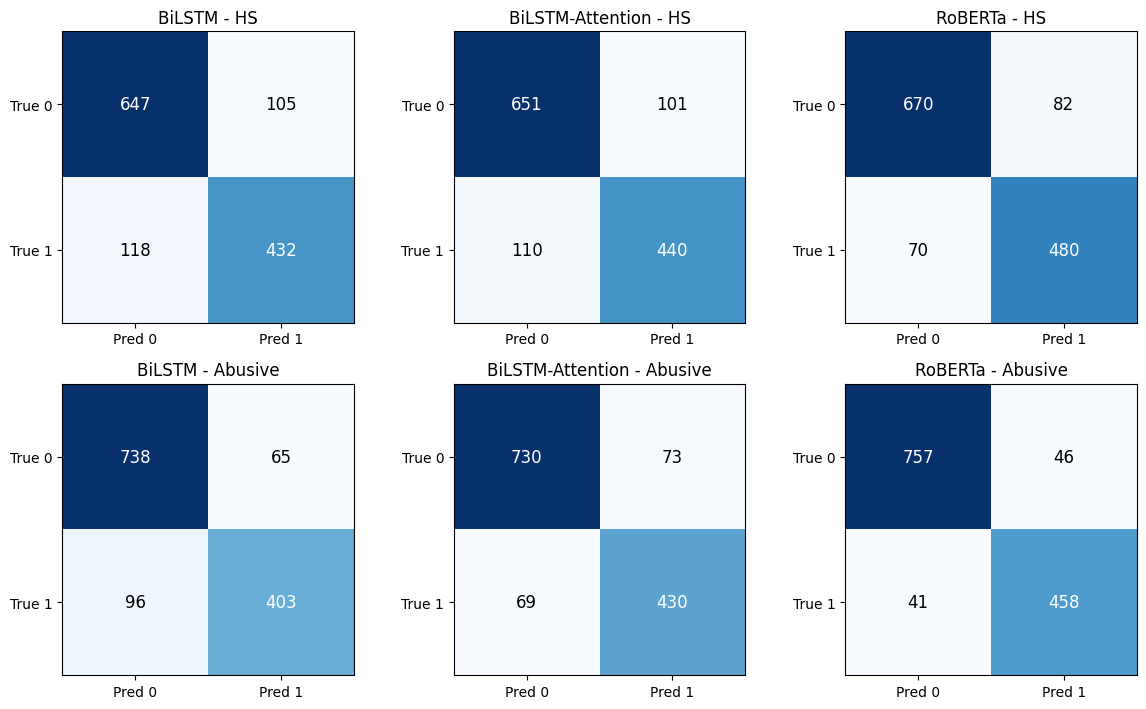

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(LABELS), len(models), figsize=(4 * len(models), 3.6 * len(LABELS)))
for col, name in enumerate(models):
    for row, label in enumerate(LABELS):
        ax = axes[row, col]
        cm = confusion_matrix(predictions[name]["labels"][:, row], predictions[name]["preds"][:, row], labels=[0, 1])
        ax.imshow(cm, cmap="Blues")
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
        ax.set_xticks([0, 1], ["Pred 0", "Pred 1"])
        ax.set_yticks([0, 1], ["True 0", "True 1"])
        ax.set_title(f"{name} - {label}")
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "confusion_matrices.png"), dpi=200)
plt.show()

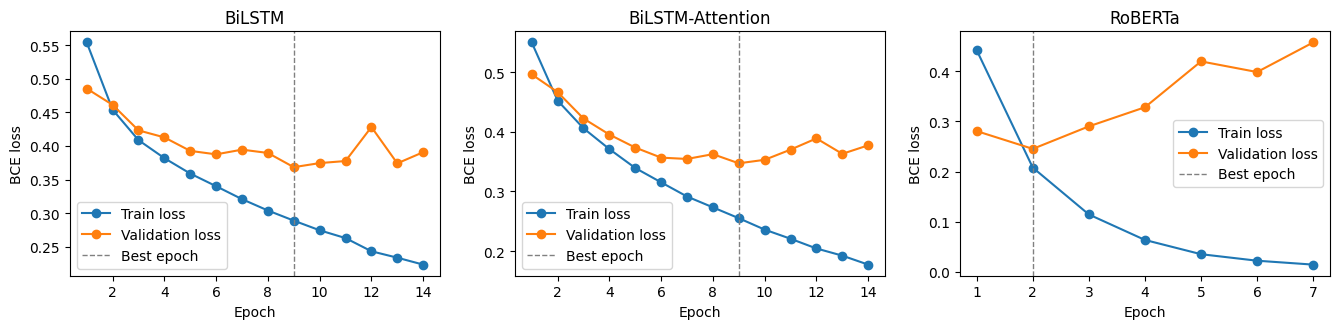

In [22]:
# Training and validation loss per epoch
fig, axes = plt.subplots(1, len(histories), figsize=(4.5 * len(histories), 3.4), sharey=False)
for ax, (name, hist) in zip(np.atleast_1d(axes), histories.items()):
    epochs = range(1, len(hist["train_loss"]) + 1)
    ax.plot(epochs, hist["train_loss"], marker="o", label="Train loss")
    ax.plot(epochs, hist["val_loss"], marker="o", label="Validation loss")
    ax.axvline(hist["best_epoch"], color="gray", linestyle="--", linewidth=1, label="Best epoch")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE loss")
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "loss_curves.png"), dpi=200)
plt.show()

In [23]:
# Attention weights of BiLSTM-Attention for a few test tweets
from IPython.display import HTML, display

@torch.no_grad()
def attention_for(text):
    bilstm_attn.eval()
    ids, length = encode(text, BILSTM_CONFIG["max_len"])
    logits, attention = bilstm_attn(torch.tensor([ids], device=DEVICE), torch.tensor([length]), return_attention=True)
    tokens = tokenize(text)[:length] or [UNK_TOKEN]
    return tokens, attention[0, :length].cpu().numpy(), torch.sigmoid(logits)[0].cpu().numpy()

def show_attention(text, true_labels):
    tokens, weights, probs = attention_for(text)
    scaled = weights / weights.max()
    spans = "".join(f'<span style="background: rgba(42,120,214,{w:.2f}); padding:2px 3px; margin:1px; '
                    f'border-radius:3px">{tok}</span>' for tok, w in zip(tokens, scaled))
    info = (f"true HS={true_labels[0]}, Abusive={true_labels[1]} | "
            f"pred P(HS)={probs[0]:.2f}, P(Abusive)={probs[1]:.2f}")
    display(HTML(f"<div style='margin:6px 0'>{spans}<br><small>{info}</small></div>"))

for _, row in test.sample(5, random_state=SEED).iterrows():
    show_attention(row["text"], (row["HS"], row["Abusive"]))

In [24]:
y_hs = test["HS"].values
y_abusive = test["Abusive"].values

rows = []
for name, pred in predictions.items():
    pred_hs = pred["preds"][:, 0]
    false_pos = (pred_hs == 1) & (y_hs == 0)
    false_neg = (pred_hs == 0) & (y_hs == 1)
    rows.append({
        "Model": name,
        "HS FP": false_pos.sum(),
        "FP that are abusive": (false_pos & (y_abusive == 1)).sum(),
        "FP abusive share": (false_pos & (y_abusive == 1)).sum() / false_pos.sum(),
        "HS FN": false_neg.sum(),
        "FN without abusive words": (false_neg & (y_abusive == 0)).sum(),
        "FN non-abusive share": (false_neg & (y_abusive == 0)).sum() / false_neg.sum(),
    })

error_df = pd.DataFrame(rows).set_index("Model")
print("Reference: abusive share among non-HS =", round((y_abusive[y_hs == 0] == 1).mean(), 3),
      "| non-abusive share among HS =", round((y_abusive[y_hs == 1] == 0).mean(), 3))
error_df.round(3)

Reference: abusive share among non-HS = 0.231 | non-abusive share among HS = 0.409


,HS FP,FP that are abusive,FP abusive share,HS FN,FN without abusive words,FN non-abusive share
Model,,,,,,
BiLSTM,105,37,0.352,118,44,0.373
BiLSTM-Attention,101,36,0.356,110,50,0.455
RoBERTa,82,36,0.439,70,28,0.400


In [25]:
roberta_pred_hs = predictions["RoBERTa"]["preds"][:, 0]
errors = test.assign(pred_HS=roberta_pred_hs, prob_HS=predictions["RoBERTa"]["probs"][:, 0].round(2))

print("=== Missed hate speech (FN) ===")
display(errors[(errors["HS"] == 1) & (errors["pred_HS"] == 0)][["text", "Abusive", "prob_HS"]].head(8))
print("=== Wrongly flagged as hate speech (FP) ===")
display(errors[(errors["HS"] == 0) & (errors["pred_HS"] == 1)][["text", "Abusive", "prob_HS"]].head(8))

=== Missed hate speech (FN) ===


,text,Abusive,prob_HS
9542,USER USER Dari rakyat oleh rakyat dan untuk ra...,1,0.33
11755,USER USER Keadilan .. Bilang ke org laen anti ...,0,0.39
12932,Kalo Gubernur AHOK masih eksis trus ada kasus ...,0,0.42
9078,USER USER Wakil gubernur 1 tingkalakunya dalam...,1,0.20
1419,"USER Dulu waktu kampanye pak jokowi,berkoar2 m...",1,0.10
8021,USER USER Memang benar!!! Kami ingin ganti!! M...,0,0.15
6560,"USER Lo kalo mau jadi jablay pro, belajar dulu...",1,0.32
3828,USER USER USER Baca deh QS Al Maidah ; 48....A...,0,0.41


=== Wrongly flagged as hate speech (FP) ===


,text,Abusive,prob_HS
3666,"USER Dia bukan lucu lagi tapi udah sarap, bawa...",1,0.56
6507,USER USER USER USER Dengan demikian siapa yg a...,0,0.96
559,USER USER USER Kenapa pak prabowo suka kampany...,1,0.53
1755,"USER USER USER Weh gimana ini,bisa gawat citra...",1,0.96
10833,"USER hey, banyak orang munafik jaman sekarang ...",0,0.84
1585,Gue gamau nyindir tapi jadi kesannya jadi nyin...,1,0.51
257,"USER Pak USER walaupun Anda Muslim, sebagai pe...",0,0.53
2778,Utang bank asing demi bli saham Freeport.G bis...,0,0.66


In [26]:
attn_pred_hs = predictions["BiLSTM-Attention"]["preds"][:, 0]
attn_view = test.assign(pred_HS=attn_pred_hs)

print("=== Hate speech correctly detected (TP) ===")
for _, row in attn_view[(attn_view["HS"] == 1) & (attn_view["pred_HS"] == 1)].sample(3, random_state=SEED).iterrows():
    show_attention(row["text"], (row["HS"], row["Abusive"]))

print("=== Hate speech missed (FN) ===")
for _, row in attn_view[(attn_view["HS"] == 1) & (attn_view["pred_HS"] == 0)].sample(3, random_state=SEED).iterrows():
    show_attention(row["text"], (row["HS"], row["Abusive"]))

=== Hate speech correctly detected (TP) ===


=== Hate speech missed (FN) ===
